In [4]:
!pip install numpy<2


Le fichier spécifié est introuvable.


In [3]:
# 📦 Imports
import pyodbc
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.1.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\ipykernel\kernelapp.py", line 736, in start
    self.io_loop.start()
  File "C:\Users\aya

AttributeError: _ARRAY_API not found

ImportError: numpy.core.multiarray failed to import

In [2]:
# 🔗 Connexion SQL Server
conn_str = (
    "Driver={ODBC Driver 17 for SQL Server};"
    "Server=LAPTOP-GPVK1ANC;"
    "Database=DW_SupplyChain;"
    "Trusted_Connection=yes;"
)
cnxn = pyodbc.connect(conn_str)

# 📥 Extraction des données
query = """
SELECT 
    productFK,
    brandFK,
    Production_Start_Time,
    Production_End_Time,
    manufacturedate,
    expirydate,
    Dosage,
    quantityused
FROM fact_production
"""
df = pd.read_sql(query, cnxn)

# Affichage des premières lignes du dataframe pour vérifier la structure des données
df.head()


C:\Users\ayadi\AppData\Local\Temp\ipykernel_25004\2065644576.py:23: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, cnxn)


,productFK,brandFK,Production_Start_Time,Production_End_Time,manufacturedate,expirydate,Dosage,quantityused
0,2,15,2022032723,2022032800,2024082023,2025083023,9,9
1,2,15,2022040823,2022040806,2024082023,2025083023,9,9
2,2,15,2022050523,2022050517,2024082023,2025083023,9,9
3,2,15,2022052123,2022052119,2024082023,2025083023,9,9
4,2,15,2022070123,2022070113,2024082023,2025083023,9,9


Description des données :
          productFK       brandFK  Production_Start_Time  Production_End_Time  \
count  33043.000000  33043.000000           3.304300e+04         3.304300e+04   
mean    2227.981902     27.311049           2.023076e+09         2.023076e+09   
std     1379.514653     38.634859           8.181835e+05         8.182656e+05   
min        2.000000      1.000000           2.022010e+09         2.022010e+09   
25%     1018.000000     11.000000           2.022101e+09         2.022101e+09   
50%     2188.000000     14.000000           2.023071e+09         2.023071e+09   
75%     3428.000000     17.000000           2.024041e+09         2.024041e+09   
max     4665.000000    200.000000           2.024123e+09         2.025010e+09   

       manufacturedate    expirydate        Dosage  
count     3.304300e+04  3.304300e+04  33043.000000  
mean      2.024076e+09  2.025553e+09      5.416427  
std       1.030576e+05  5.115086e+05      2.912770  
min       2.024010e+09  2.025010

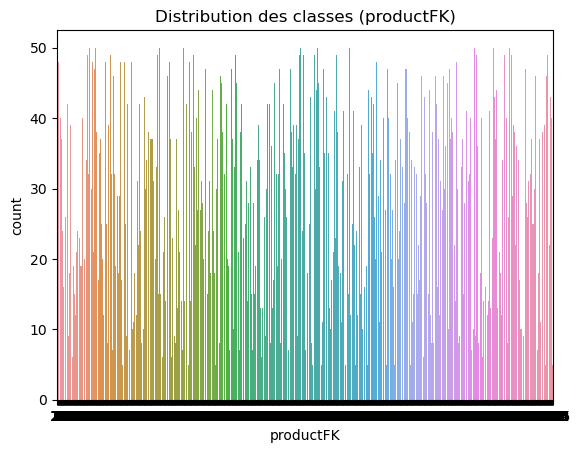

In [5]:
# 🧐 Exploration des données
print("Description des données :")
print(df.describe())

# Vérification des valeurs manquantes
print("\nValeurs manquantes dans chaque colonne :")
print(df.isnull().sum())

# Visualisation de la distribution des données de la cible
sns.countplot(x='productFK', data=df)
plt.title('Distribution des classes (productFK)')
plt.show()


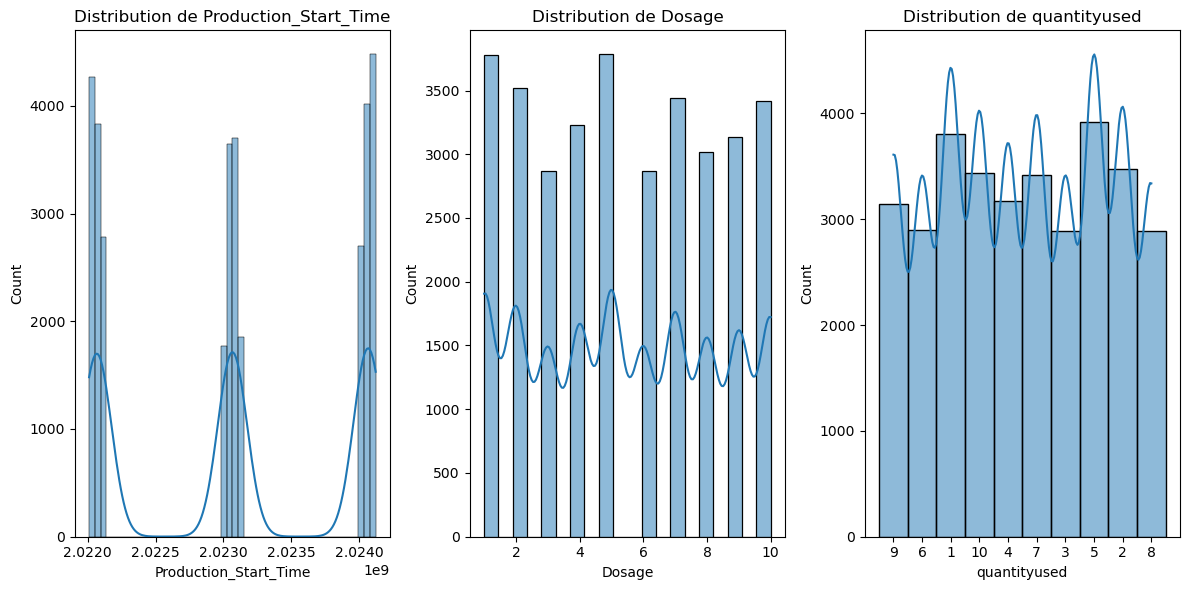

In [6]:
# 🧐 Visualisation des distributions des variables numériques
plt.figure(figsize=(12, 6))

# Distribution de Production_Start_Time
plt.subplot(1, 3, 1)
sns.histplot(df['Production_Start_Time'], bins=50, kde=True)
plt.title('Distribution de Production_Start_Time')

# Distribution de Dosage
plt.subplot(1, 3, 2)
sns.histplot(df['Dosage'], bins=20, kde=True)
plt.title('Distribution de Dosage')

# Distribution de quantityused
plt.subplot(1, 3, 3)
sns.histplot(df['quantityused'], bins=20, kde=True)
plt.title('Distribution de quantityused')

plt.tight_layout()
plt.show()


In [7]:
# 🔀 Séparation des variables caractéristiques et cible
X = df.drop('productFK', axis=1)  # Supprimer 'productFK' de X, c'est notre variable cible
y = df['productFK']  # 'productFK' est la cible

# Conversion de 'Production_Start_Time', 'Production_End_Time', 'manufacturedate', 'expirydate' en datetime
X['Production_Start_Time'] = pd.to_datetime(X['Production_Start_Time'], unit='s')
X['Production_End_Time'] = pd.to_datetime(X['Production_End_Time'], unit='s')
X['manufacturedate'] = pd.to_datetime(X['manufacturedate'], unit='s')
X['expirydate'] = pd.to_datetime(X['expirydate'], unit='s')

# Vérification des changements
X.head()


,brandFK,Production_Start_Time,Production_End_Time,manufacturedate,expirydate,Dosage,quantityused
0,15,2034-01-28 03:45:23,2034-01-28 03:46:40,2034-02-20 21:00:23,2034-03-04 11:03:43,9,9
1,15,2034-01-28 06:00:23,2034-01-28 06:00:06,2034-02-20 21:00:23,2034-03-04 11:03:43,9,9
2,15,2034-01-28 08:42:03,2034-01-28 08:41:57,2034-02-20 21:00:23,2034-03-04 11:03:43,9,9
3,15,2034-01-28 09:08:43,2034-01-28 09:08:39,2034-02-20 21:00:23,2034-03-04 11:03:43,9,9
4,15,2034-01-28 14:08:43,2034-01-28 14:08:33,2034-02-20 21:00:23,2034-03-04 11:03:43,9,9


In [8]:
# 📊 Division des données en ensembles d'entraînement et de test (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Affichage de la taille des ensembles
print(f"Taille des données d'entraînement : {X_train.shape}")
print(f"Taille des données de test : {X_test.shape}")


Taille des données d'entraînement : (26434, 7)
Taille des données de test : (6609, 7)


In [9]:
# 🔧 Extraction des caractéristiques temporelles
X_train['production_duration'] = (X_train['Production_End_Time'] - X_train['Production_Start_Time']).dt.total_seconds()
X_test['production_duration'] = (X_test['Production_End_Time'] - X_test['Production_Start_Time']).dt.total_seconds()

X_train['product_lifetime'] = (X_train['expirydate'] - X_train['manufacturedate']).dt.total_seconds()
X_test['product_lifetime'] = (X_test['expirydate'] - X_test['manufacturedate']).dt.total_seconds()

# Suppression des colonnes de dates originales
X_train = X_train.drop(['Production_Start_Time', 'Production_End_Time', 'manufacturedate', 'expirydate'], axis=1)
X_test = X_test.drop(['Production_Start_Time', 'Production_End_Time', 'manufacturedate', 'expirydate'], axis=1)

# Affichage des premières lignes pour vérifier la transformation
X_train.head()


,brandFK,Dosage,quantityused,production_duration,product_lifetime
20270,17,4,4,77.0,1030600.0
11057,10,2,2,-19.0,1052200.0
30096,10,7,7,-9.0,1958700.0
4253,145,3,3,-8.0,1921700.0
25303,15,10,10,-1.0,1039500.0


In [10]:
# 🔧 Normalisation des caractéristiques (moyenne = 0, écart-type = 1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Vérification de la normalisation
print(f"Moyenne des données d'entraînement après normalisation : {np.mean(X_train_scaled, axis=0)}")
print(f"Écart-type des données d'entraînement après normalisation : {np.std(X_train_scaled, axis=0)}")


Moyenne des données d'entraînement après normalisation : [ 4.08574169e-17 -1.09401110e-16  6.26301193e-17 -2.41918916e-18
  8.25212302e-17]
Écart-type des données d'entraînement après normalisation : [1. 1. 1. 1. 1.]


In [11]:
# 🤖 Entraînement du modèle RandomForest
model = RandomForestClassifier(random_state=42)

# Entraînement du modèle
model.fit(X_train_scaled, y_train)

# Affichage des résultats de l'entraînement
print("Entraînement du modèle terminé.")


Entraînement du modèle terminé.


In [12]:
# 🔮 Prédictions sur les données de test
y_pred = model.predict(X_test_scaled)

# Affichage des premières prédictions
print(f"Premières prédictions : {y_pred[:10]}")


Premières prédictions : [3129 2013  412 1676 2060 1547  729 2718 3466 2208]


In [ ]:
# 📊 Rapport de classification
print("Rapport de classification :")
print(classification_report(y_test, y_pred))

# 📉 Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Matrice de Confusion")
plt.xlabel("Prédictions")
plt.ylabel("Véritables classes")
plt.show()

In [ ]:
# 🔍 Importance des caractéristiques
feature_importances = model.feature_importances_
features = X.columns

# Création d'un DataFrame pour afficher l'importance des caractéristiques
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': feature_importances
})

# Affichage des caractéristiques les plus importantes
importance_df = importance_df.sort_values(by='Importance', ascending=False)
print("Importance des caractéristiques :")
print(importance_df)
